# Projeto FINOR — Index Tracking (S&P 100 e IBOVESPA)
**Bootcamp Data Science 2026 | Grupo 2 (Manhã)**

Notebook consolidado do projeto. Contém o pipeline completo: coleta e limpeza dos dados históricos (2022–2026), análise exploratória (EDA), engenharia de atributos sem vazamento temporal (*data leakage*), comparação de famílias de algoritmos (*spot-checking*) e validação *walk-forward* com controle de giro (*turnover*) e custos de transação.


## 1. Configuração do Ambiente e Padrão Visual


In [14]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize
from sklearn.linear_model import Lasso
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from IPython.display import display

np.random.seed(42)

def set_nyt_style():
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['figure.facecolor'] = '#FFFFFF'
    plt.rcParams['axes.facecolor'] = '#FFFFFF'
    plt.rcParams['axes.edgecolor'] = '#CCCCCC'
    plt.rcParams['axes.linewidth'] = 0.8
    plt.rcParams['grid.color'] = '#E5E5E5'
    plt.rcParams['grid.linestyle'] = '--'
    plt.rcParams['grid.alpha'] = 0.7
    plt.rcParams['axes.spines.top'] = False
    plt.rcParams['axes.spines.right'] = False
    plt.rcParams['axes.spines.left'] = True
    plt.rcParams['axes.spines.bottom'] = True
    plt.rcParams['xtick.color'] = '#333333'
    plt.rcParams['ytick.color'] = '#333333'
    plt.rcParams['axes.labelcolor'] = '#222222'
    plt.rcParams['axes.titlesize'] = 13
    plt.rcParams['axes.titleweight'] = 'bold'

set_nyt_style()

CORES = {
    'sp100': '#0F4C81',      # Azul Marinho (S&P 100)
    'sp100_sec': '#2B6999',  # Azul Secundário
    'ibov': '#1B4D3E',       # Verde Esmeralda (IBOVESPA)
    'ibov_sec': '#2E7D67',   # Verde Secundário
    'alerta': '#C53030',     # Vermelho para cortes e destaques
    'laranja': '#D97706',    # Âmbar para comparação de modelos
    'neutro': '#A0AEC0',     # Cinza para contexto e baselines
    'grafite': '#1A202C'     # Benchmark
}


## 2. Coleta, Diagnóstico de Completude e Limpeza dos Dados
Os dados compreendem o período de janeiro de 2022 a outubro de 2026. Caso os arquivos CSV já estejam salvos localmente no diretório, o carregamento é feito direto do disco para evitar downloads repetidos e garantir reprodutibilidade.


In [15]:
ticker_idx_sp100 = '^OEX'
ticker_idx_ibov = '^BVSP'
data_inicio = "2022-01-01"
data_fim = "2026-10-02"

SP100_meta = pd.read_csv("SP100_wikipedia_21set2026.csv")
tickers_sp100 = SP100_meta["Symbol"].str.strip().tolist()

IBOV_meta = pd.read_csv("IBOVESPA_B3_24set2026.csv")
tickers_ibov = [t.strip() + ".SA" for t in IBOV_meta["Codigo"].tolist()]

# Se os CSVs já existirem localmente, carrega do disco; caso contrário, baixa via yfinance
if os.path.exists('sp100_precos.csv') and os.path.exists('ibov_precos.csv'):
    print("Carregando bases de preços a partir dos arquivos CSV locais...")
    dados_sp100 = pd.read_csv('sp100_precos.csv', index_col='Date', parse_dates=True)
    dados_ibov = pd.read_csv('ibov_precos.csv', index_col='Date', parse_dates=True)
    indice_sp100 = pd.read_csv('sp100_indice.csv', index_col='Date', parse_dates=True)
    indice_ibov = pd.read_csv('ibov_indice.csv', index_col='Date', parse_dates=True)
else:
    print("Baixando séries históricas do Yahoo Finance...")
    dados_sp100 = yf.download(tickers_sp100, start=data_inicio, end=data_fim, auto_adjust=True, progress=False)['Close']
    indice_sp100 = yf.download(ticker_idx_sp100, start=data_inicio, end=data_fim, auto_adjust=True, progress=False)['Close']
    dados_ibov = yf.download(tickers_ibov, start=data_inicio, end=data_fim, auto_adjust=True, progress=False)['Close']
    indice_ibov = yf.download(ticker_idx_ibov, start=data_inicio, end=data_fim, auto_adjust=True, progress=False)['Close']

    dados_sp100.to_csv('sp100_precos.csv')
    dados_ibov.to_csv('ibov_precos.csv')
    indice_sp100.to_csv('sp100_indice.csv')
    indice_ibov.to_csv('ibov_indice.csv')

print(f"S&P 100 : {dados_sp100.shape[1]} ativos x {dados_sp100.shape[0]} pregões ({dados_sp100.index[0].date()} a {dados_sp100.index[-1].date()})")
print(f"IBOVESPA: {dados_ibov.shape[1]} ativos x {dados_ibov.shape[0]} pregões ({dados_ibov.index[0].date()} a {dados_ibov.index[-1].date()})")


Carregando bases de preços a partir dos arquivos CSV locais...
S&P 100 : 101 ativos x 1191 pregões (2022-01-03 a 2026-10-01)
IBOVESPA: 76 ativos x 1187 pregões (2022-01-03 a 2026-10-01)


### 2.1 Diagnóstico e Filtro de Dados Faltantes
Ativos com mais de 5% de pregões ausentes (tipicamente decorrentes de IPOs recentes ou reestruturações societárias, como `SNDK` e `GEV` no S&P 100 e `NATU3.SA` no IBOVESPA) são removidos. Falhas pontuais inferiores a 5% são preenchidas via *forward fill* (`ffill`), evitando vazamento de preços futuros.


In [16]:
limite_remocao = 5.0

pct_nulos_sp = (dados_sp100.isnull().mean() * 100).round(2)
pct_nulos_ib = (dados_ibov.isnull().mean() * 100).round(2)

print("=== Ativos com dados faltantes (> 0%) — S&P 100 ===")
print(pct_nulos_sp[pct_nulos_sp > 0].sort_values(ascending=False))

print("\n=== Ativos com dados faltantes (> 0%) — IBOVESPA ===")
print(pct_nulos_ib[pct_nulos_ib > 0].sort_values(ascending=False))

# Filtragem e preenchimento apenas para frente (ffill)
acoes_validas_sp = pct_nulos_sp[pct_nulos_sp <= limite_remocao].index
acoes_validas_ib = pct_nulos_ib[pct_nulos_ib <= limite_remocao].index

dados_sp100_clean = dados_sp100[acoes_validas_sp].ffill().dropna(how='any')
dados_ibov_clean = dados_ibov[acoes_validas_ib].ffill().dropna(how='any')

# Cálculo dos retornos logarítmicos nos dados limpos
ret_sp100_clean = np.log(dados_sp100_clean / dados_sp100_clean.shift(1)).dropna(how='any')
ret_ibov_clean = np.log(dados_ibov_clean / dados_ibov_clean.shift(1)).dropna(how='any')

ret_idx_sp = np.log(indice_sp100.ffill() / indice_sp100.ffill().shift(1)).dropna().squeeze()
ret_idx_ib = np.log(indice_ibov.ffill() / indice_ibov.ffill().shift(1)).dropna().squeeze()
if isinstance(ret_idx_sp, pd.DataFrame): ret_idx_sp = ret_idx_sp.iloc[:, 0]
if isinstance(ret_idx_ib, pd.DataFrame): ret_idx_ib = ret_idx_ib.iloc[:, 0]

# Alinhamento de calendário entre ações e respectivo índice
comum_sp = ret_sp100_clean.index.intersection(ret_idx_sp.index)
ret_sp100_clean = ret_sp100_clean.loc[comum_sp]
ret_idx_sp = ret_idx_sp.loc[comum_sp]

comum_ib = ret_ibov_clean.index.intersection(ret_idx_ib.index)
ret_ibov_clean = ret_ibov_clean.loc[comum_ib]
ret_idx_ib = ret_idx_ib.loc[comum_ib]

ret_sp100_clean.to_csv('sp100_retornos_limpos.csv')
ret_ibov_clean.to_csv('ibov_retornos_limpos.csv')

print(f"\nMatrizes limpas prontas -> S&P 100: {ret_sp100_clean.shape} | IBOVESPA: {ret_ibov_clean.shape}")


=== Ativos com dados faltantes (> 0%) — S&P 100 ===
SNDK    65.58
GEV     47.02
dtype: float64

=== Ativos com dados faltantes (> 0%) — IBOVESPA ===
NATU3.SA    73.13
AURE3.SA     4.89
dtype: float64

Matrizes limpas prontas -> S&P 100: (1190, 99) | IBOVESPA: (1128, 75)


## 3. Análise Exploratória de Dados (EDA)
Comparação direta de risco e retorno entre os dois mercados, distribuição de retornos diários (caudas pesadas) e estrutura de correlação setorial.


,S&P 100 (^OEX),IBOVESPA (^BVSP)
Retorno Anualizado,17.09%,10.77%
Volatilidade Anualizada,17.75%,17.05%
Sharpe Anualizado,0.963,0.632
Retorno Acumulado Total,110.47%,59.83%
Pior Dia (Retorno Mín.),-6.13%,-4.40%
Melhor Dia (Retorno Máx.),9.71%,5.39%


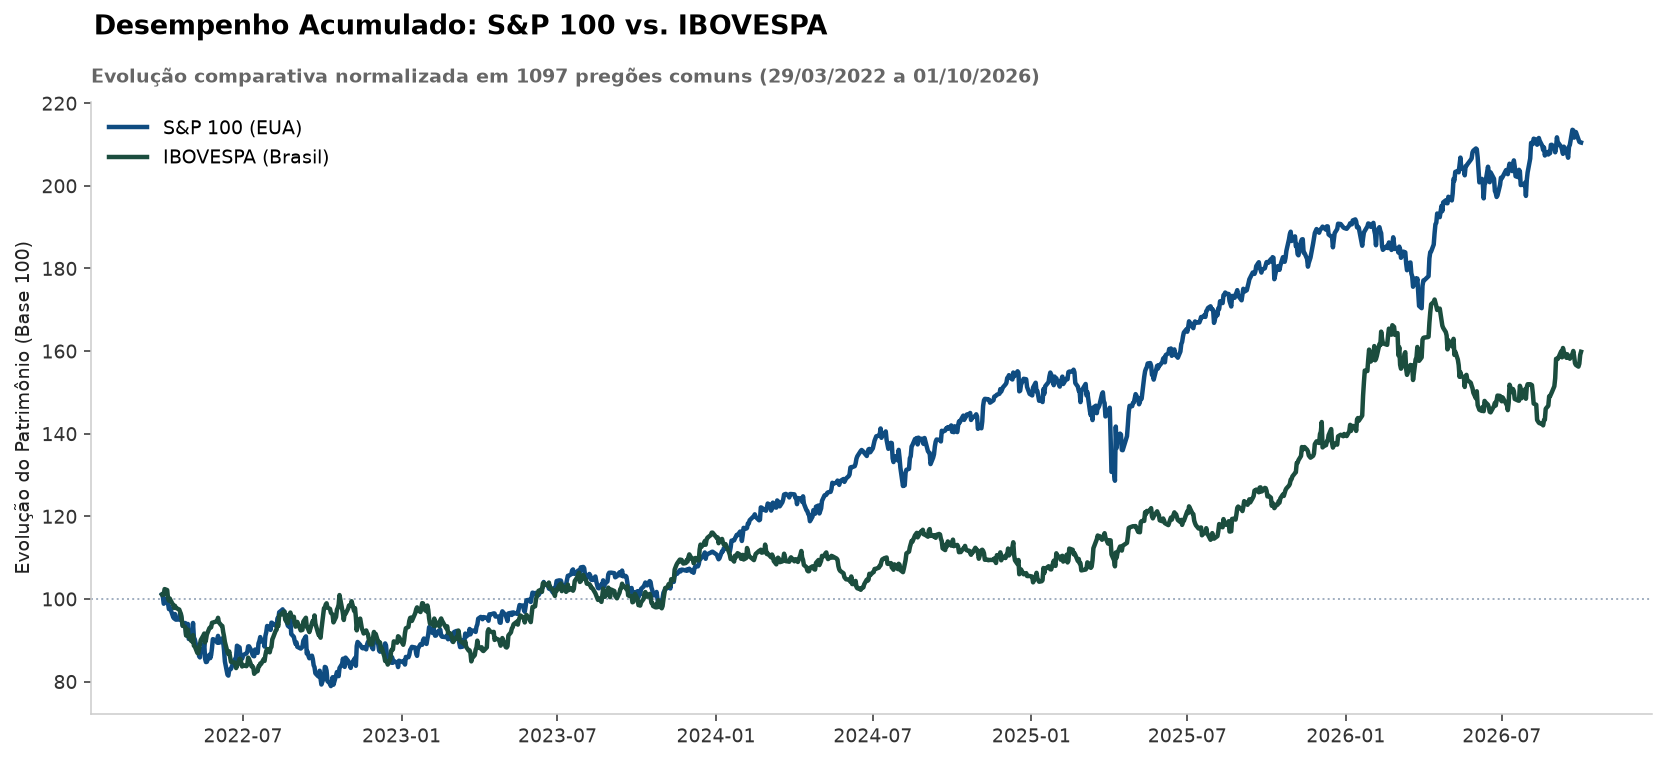

In [17]:
# 3.1 Comparativo Histórico S&P 100 vs IBOVESPA (Datas Comuns)
datas_comuns = ret_idx_sp.index.intersection(ret_idx_ib.index)
s_sp = ret_idx_sp.loc[datas_comuns]
s_ib = ret_idx_ib.loc[datas_comuns]

sp_acum = np.exp(s_sp.cumsum()) * 100
ib_acum = np.exp(s_ib.cumsum()) * 100

tabela_resumo = pd.DataFrame({
    'S&P 100 (^OEX)': [
        f"{s_sp.mean() * 252 * 100:.2f}%",
        f"{s_sp.std() * np.sqrt(252) * 100:.2f}%",
        f"{(s_sp.mean() / s_sp.std()) * np.sqrt(252):.3f}",
        f"{sp_acum.iloc[-1] - 100:.2f}%",
        f"{s_sp.min() * 100:.2f}%",
        f"{s_sp.max() * 100:.2f}%"
    ],
    'IBOVESPA (^BVSP)': [
        f"{s_ib.mean() * 252 * 100:.2f}%",
        f"{s_ib.std() * np.sqrt(252) * 100:.2f}%",
        f"{(s_ib.mean() / s_ib.std()) * np.sqrt(252):.3f}",
        f"{ib_acum.iloc[-1] - 100:.2f}%",
        f"{s_ib.min() * 100:.2f}%",
        f"{s_ib.max() * 100:.2f}%"
    ]
}, index=[
    'Retorno Anualizado', 'Volatilidade Anualizada', 'Sharpe Anualizado',
    'Retorno Acumulado Total', 'Pior Dia (Retorno Mín.)', 'Melhor Dia (Retorno Máx.)'
])

display(tabela_resumo)

fig, ax = plt.subplots(figsize=(12, 5.5), dpi=140)
ax.axhline(100, color=CORES['neutro'], ls=':', lw=1)
ax.plot(sp_acum.index, sp_acum, color=CORES['sp100'], lw=2.3, label='S&P 100 (EUA)')
ax.plot(ib_acum.index, ib_acum, color=CORES['ibov'], lw=2.3, label='IBOVESPA (Brasil)')
ax.set_ylabel('Evolução do Patrimônio (Base 100)')
ax.legend(frameon=False, loc='upper left')
plt.suptitle('Desempenho Acumulado: S&P 100 vs. IBOVESPA', x=0.06, y=0.98, fontweight='bold', fontsize=14, ha='left')
ax.set_title(f'Evolução comparativa normalizada em {len(datas_comuns)} pregões comuns ({datas_comuns[0].strftime("%d/%m/%Y")} a {datas_comuns[-1].strftime("%d/%m/%Y")})',
             fontsize=10, color='#666666', loc='left', pad=10)
plt.tight_layout()
plt.show()


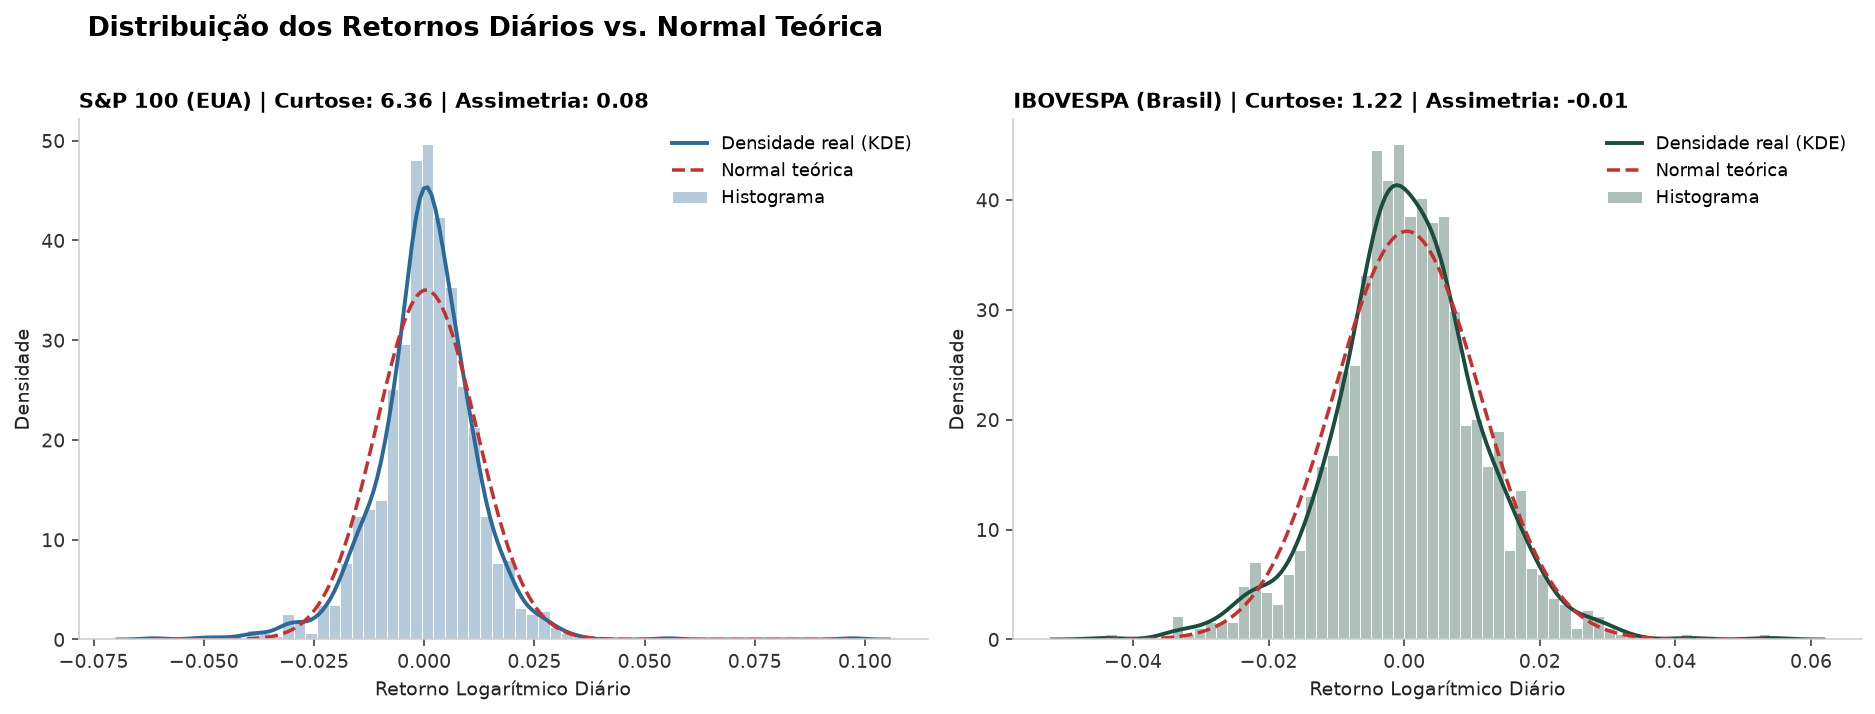

Pares altamente colineares (r > 0.90) no S&P 100: [('AMAT', 'LRCX', np.float64(0.917)), ('GOOG', 'GOOGL', np.float64(0.997))]
Pares altamente colineares (r > 0.90) no IBOVESPA: [('BBDC3.SA', 'BBDC4.SA', np.float64(0.964)), ('BRAP4.SA', 'VALE3.SA', np.float64(0.909)), ('GGBR4.SA', 'GOAU4.SA', np.float64(0.957)), ('ITSA4.SA', 'ITUB4.SA', np.float64(0.926)), ('PETR3.SA', 'PETR4.SA', np.float64(0.962))]


In [18]:
# 3.2 Distribuição de Retornos vs. Curva Normal (Fat Tails) e Pares Colineares
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5), dpi=140)

for ax, serie, nome, cor in [
    (ax1, ret_idx_sp, 'S&P 100 (EUA)', CORES['sp100_sec']),
    (ax2, ret_idx_ib, 'IBOVESPA (Brasil)', CORES['ibov'])
]:
    sns.histplot(serie, bins=60, stat='density', color=cor, alpha=0.35, edgecolor='white', ax=ax, label='Histograma')
    sns.kdeplot(serie, color=cor, lw=2, ax=ax, label='Densidade real (KDE)')
    x_val = np.linspace(serie.min(), serie.max(), 200)
    ax.plot(x_val, stats.norm.pdf(x_val, serie.mean(), serie.std()), color=CORES['alerta'], ls='--', lw=1.8, label='Normal teórica')
    ax.set_title(f"{nome} | Curtose: {serie.kurtosis():.2f} | Assimetria: {serie.skew():.2f}", loc='left', fontsize=11)
    ax.set_xlabel('Retorno Logarítmico Diário')
    ax.set_ylabel('Densidade')
    ax.legend(frameon=False, fontsize=9)

plt.suptitle('Distribuição dos Retornos Diários vs. Normal Teórica', x=0.05, y=1.01, fontweight='bold', fontsize=14, ha='left')
plt.tight_layout()
plt.show()

# Verificação de pares redundantes (Correlação > 0.90)
for nome_m, df_r in [('S&P 100', ret_sp100_clean), ('IBOVESPA', ret_ibov_clean)]:
    corr_m = df_r.corr()
    pares = []
    for i in range(len(corr_m.columns)):
        for j in range(i+1, len(corr_m.columns)):
            if corr_m.iloc[i, j] > 0.90:
                pares.append((corr_m.columns[i], corr_m.columns[j], round(corr_m.iloc[i, j], 3)))
    print(f"Pares altamente colineares (r > 0.90) no {nome_m}: {pares}")


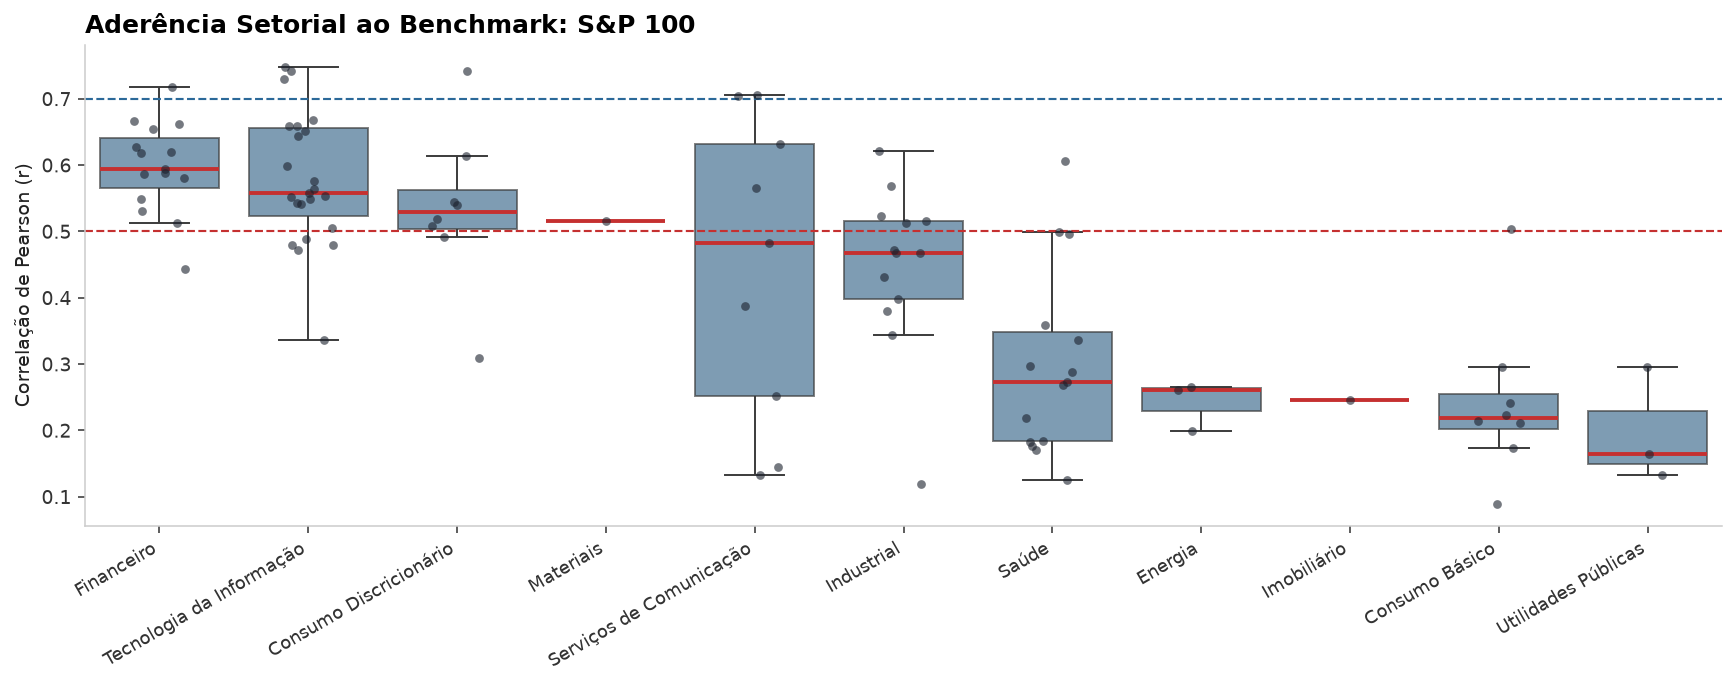

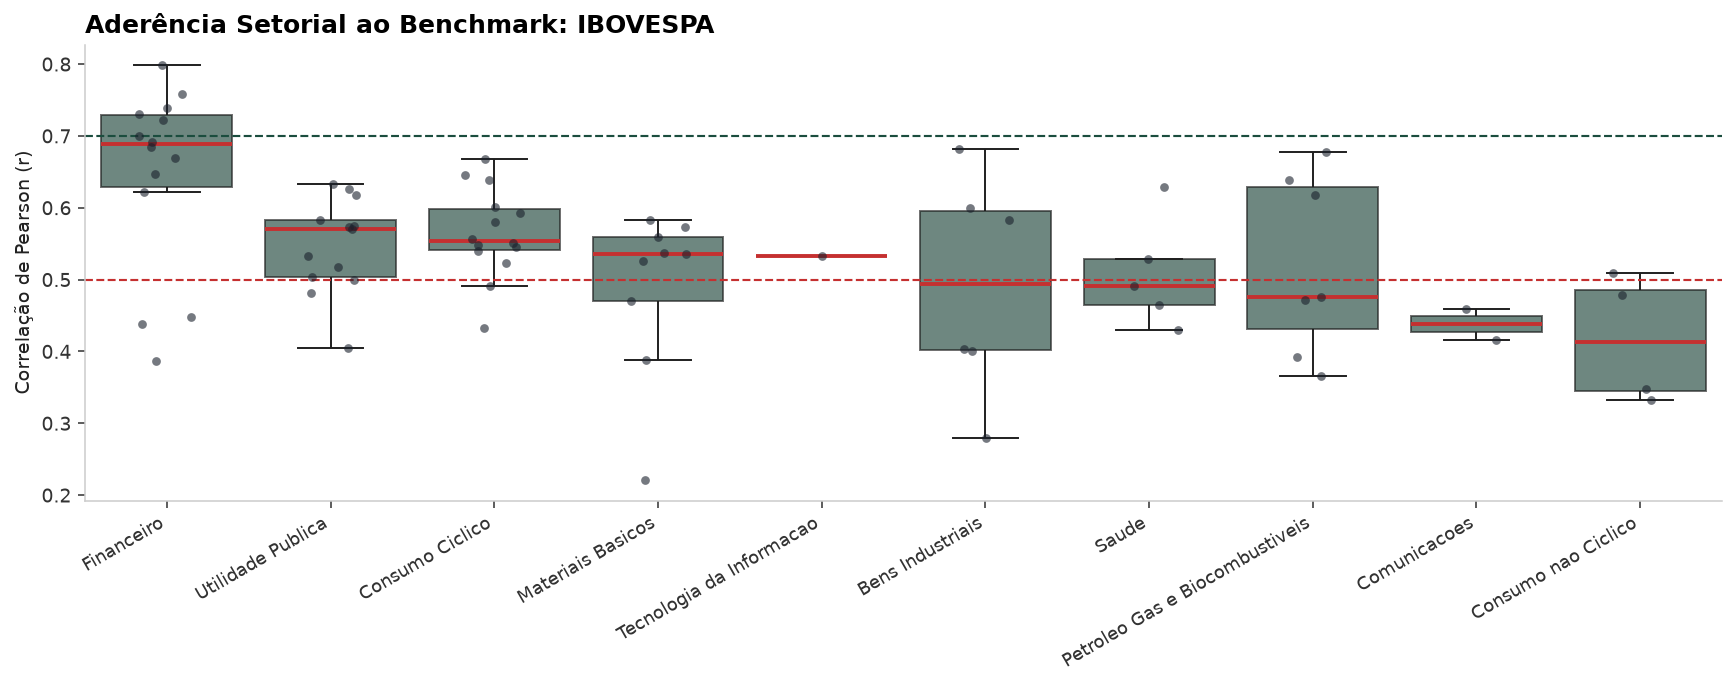

In [19]:
# 3.3 Mapeamento Setorial e Aderência ao Benchmark
traducao_sp100 = {
    'Information Technology': 'Tecnologia da Informação', 'Health Care': 'Saúde',
    'Financials': 'Financeiro', 'Industrials': 'Industrial',
    'Communication Services': 'Serviços de Comunicação', 'Consumer Discretionary': 'Consumo Discricionário',
    'Consumer Staples': 'Consumo Básico', 'Energy': 'Energia',
    'Utilities': 'Utilidades Públicas', 'Real Estate': 'Imobiliário', 'Materials': 'Materiais'
}

mapa_setores_sp = dict(zip(SP100_meta['Symbol'].str.strip(), SP100_meta['Sector'].map(lambda x: traducao_sp100.get(x, x))))
mapa_setores_ib = dict(zip(IBOV_meta['Codigo'].str.strip() + '.SA', IBOV_meta['Setor']))

for nome_m, ret_ac, ret_id, mapa_s, cor_b in [
    ('S&P 100', ret_sp100_clean, ret_idx_sp, mapa_setores_sp, CORES['sp100_sec']),
    ('IBOVESPA', ret_ibov_clean, ret_idx_ib, mapa_setores_ib, CORES['ibov'])
]:
    corr_s = ret_ac.corrwith(ret_id)
    df_s = pd.DataFrame({'Ativo': corr_s.index, 'Pearson_R': corr_s.values})
    df_s['Setor'] = df_s['Ativo'].map(mapa_s).fillna('Outros')
    ordem = df_s.groupby('Setor')['Pearson_R'].median().sort_values(ascending=False).index

    fig, ax = plt.subplots(figsize=(12.5, 5), dpi=140)
    sns.boxplot(data=df_s, x='Setor', y='Pearson_R', order=ordem, color=cor_b,
                boxprops=dict(alpha=0.65), medianprops=dict(color=CORES['alerta'], lw=2), fliersize=0, ax=ax)
    sns.stripplot(data=df_s, x='Setor', y='Pearson_R', order=ordem, color='#1A202C', alpha=0.6, jitter=0.18, size=4.5, ax=ax)
    ax.axhline(0.70, color=cor_b, ls='--', lw=1.1)
    ax.axhline(0.50, color=CORES['alerta'], ls='--', lw=1.1)
    ax.tick_params(axis='x', rotation=30, labelsize=9)
    plt.xticks(ha='right')
    ax.set_ylabel('Correlação de Pearson (r)')
    ax.set_xlabel('')
    ax.set_title(f'Aderência Setorial ao Benchmark: {nome_m}', loc='left', fontweight='bold', fontsize=13)
    plt.tight_layout()
    plt.show()


## 4. Divisão Temporal e Engenharia de Atributos (Feature Engineering)
Para impedir vazamento de dados (*data leakage* / *look-ahead bias*), dividimos a série cronologicamente antes de calcular qualquer estatística de seleção:
* **Treino (`até 31/12/2024`):** Utilizado para calcular *features* por ativo, rodar o diagnóstico de PCA, selecionar ações e calibrar os pesos no *spot-checking*.
* **Fora da Amostra / Teste (`01/01/2025 a 01/10/2026`):** Período que o modelo nunca viu, usado para comparar as arquiteturas candidatas.


In [20]:
DATA_CORTE_TREINO = '2024-12-31'

def dividir_treino_teste(ret_acoes, ret_idx):
    treino_X = ret_acoes.loc[:DATA_CORTE_TREINO]
    treino_y = ret_idx.loc[:DATA_CORTE_TREINO]
    oos_X = ret_acoes.loc[DATA_CORTE_TREINO:].iloc[1:]
    oos_y = ret_idx.loc[oos_X.index]
    return treino_X, treino_y, oos_X, oos_y

tr_X_sp, tr_y_sp, oos_X_sp, oos_y_sp = dividir_treino_teste(ret_sp100_clean, ret_idx_sp)
tr_X_ib, tr_y_ib, oos_X_ib, oos_y_ib = dividir_treino_teste(ret_ibov_clean, ret_idx_ib)

print(f"S&P 100  -> Treino: {len(tr_X_sp)} pregões | Fora da Amostra (2025-2026): {len(oos_X_sp)} pregões")
print(f"IBOVESPA -> Treino: {len(tr_X_ib)} pregões | Fora da Amostra (2025-2026): {len(oos_X_ib)} pregões")

def construir_features_treino(treino_X, treino_y, mapa_setores):
    """Constrói a tabela de atributos de risco e aderência usando apenas dados de treino."""
    var_idx = treino_y.var()
    vol_idx = treino_y.std() * np.sqrt(252)
    corr_matrix = treino_X.corr()

    feats = pd.DataFrame(index=treino_X.columns)
    feats['corr_idx'] = treino_X.corrwith(treino_y)
    feats['beta'] = treino_X.apply(lambda s: s.cov(treino_y) / var_idx)
    feats['vol_anual'] = treino_X.std() * np.sqrt(252)
    feats['vol_ratio_idx'] = feats['vol_anual'] / vol_idx
    feats['te_ind'] = treino_X.sub(treino_y, axis=0).std() * np.sqrt(252)
    feats['corr_media_pares'] = (corr_matrix.sum() - 1.0) / (len(corr_matrix) - 1)

    acum = np.exp(treino_X.cumsum())
    pico = acum.cummax()
    feats['max_drawdown'] = ((acum - pico) / pico).min()
    feats['setor'] = feats.index.map(mapa_setores).fillna('Outros')
    return feats.sort_values('corr_idx', ascending=False)

feats_sp = construir_features_treino(tr_X_sp, tr_y_sp, mapa_setores_sp)
feats_ib = construir_features_treino(tr_X_ib, tr_y_ib, mapa_setores_ib)

print("\nTop 5 Ações por Correlação no Treino — S&P 100:")
display(feats_sp.head(5).round(4))

print("\nTop 5 Ações por Correlação no Treino — IBOVESPA:")
display(feats_ib.head(5).round(4))


S&P 100  -> Treino: 752 pregões | Fora da Amostra (2025-2026): 438 pregões
IBOVESPA -> Treino: 690 pregões | Fora da Amostra (2025-2026): 437 pregões

Top 5 Ações por Correlação no Treino — S&P 100:


,corr_idx,beta,vol_anual,vol_ratio_idx,te_ind,corr_media_pares,max_drawdown,setor
MSFT,0.8296,1.2463,0.2758,1.5024,0.1605,0.3718,-0.3445,Tecnologia da Informação
AAPL,0.8095,1.1928,0.2705,1.4734,0.1627,0.3814,-0.3002,Tecnologia da Informação
AMZN,0.7673,1.6029,0.3835,2.0890,0.2697,0.3474,-0.5168,Consumo Discricionário
NVDA,0.7541,2.2454,0.5466,2.9775,0.4256,0.3230,-0.6164,Tecnologia da Informação
INTU,0.7539,1.4956,0.3642,1.9838,0.2560,0.3851,-0.4271,Tecnologia da Informação



Top 5 Ações por Correlação no Treino — IBOVESPA:


,corr_idx,beta,vol_anual,vol_ratio_idx,te_ind,corr_media_pares,max_drawdown,setor
ITSA4.SA,0.7634,0.9291,0.2110,1.2170,0.1369,0.4223,-0.2516,Financeiro
CSAN3.SA,0.7378,1.4115,0.3317,1.9131,0.2350,0.4107,-0.6339,Petroleo Gas e Biocombustiveis
ITUB4.SA,0.7206,0.9331,0.2245,1.2949,0.1561,0.3889,-0.2376,Financeiro
BPAC11.SA,0.7130,1.4164,0.3444,1.9864,0.2521,0.4204,-0.3680,Financeiro
B3SA3.SA,0.7051,1.4691,0.3613,2.0837,0.2688,0.4184,-0.3836,Financeiro


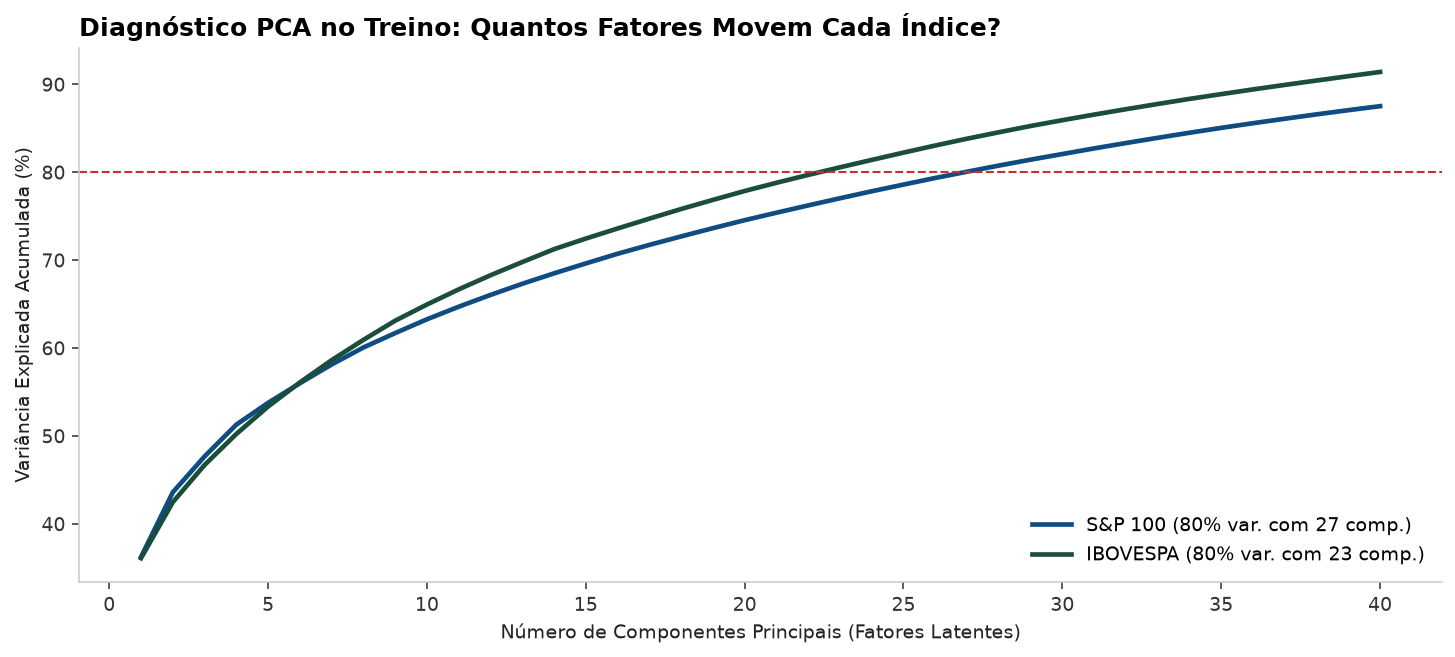

In [21]:
# 4.1 Diagnóstico de Dimensionalidade Efetiva via PCA (Treino)
pca_sp = PCA().fit(tr_X_sp)
pca_ib = PCA().fit(tr_X_ib)
var_sp = np.cumsum(pca_sp.explained_variance_ratio_) * 100
var_ib = np.cumsum(pca_ib.explained_variance_ratio_) * 100

n80_sp = int(np.searchsorted(var_sp, 80.0) + 1)
n80_ib = int(np.searchsorted(var_ib, 80.0) + 1)

fig, ax = plt.subplots(figsize=(10.5, 4.8), dpi=140)
ax.plot(range(1, 41), var_sp[:40], color=CORES['sp100'], lw=2.4, label=f'S&P 100 (80% var. com {n80_sp} comp.)')
ax.plot(range(1, 41), var_ib[:40], color=CORES['ibov'], lw=2.4, label=f'IBOVESPA (80% var. com {n80_ib} comp.)')
ax.axhline(80, color=CORES['alerta'], ls='--', lw=1.1)
ax.set_xlabel('Número de Componentes Principais (Fatores Latentes)')
ax.set_ylabel('Variância Explicada Acumulada (%)')
ax.legend(frameon=False, loc='lower right')
ax.set_title('Diagnóstico PCA no Treino: Quantos Fatores Movem Cada Índice?', loc='left', fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Spot-Checking: Comparação de 6 Famílias de Modelos
Testamos seis abordagens para resolver o problema combinatório de escolher $K$ ativos e definir seus pesos ($w_i \ge 0, \sum w_i = 1$):
1. **Baseline 1 (Top $K$ Correlação + Pesos Iguais $1/K$):** Alocação uniforme nas $K$ ações mais correlacionadas.
2. **Baseline 2 (Top $K$ Correlação + Inverso da Volatilidade $1/\sigma_i$):** Reduz analiticamente o peso de ações hipervoláteis.
3. **SLSQP Puro (Filtro de Colinearidade $r < 0,90$ + Minimização de MSE):** Otimização quadrática restrita clássica.
4. **SLSQP + Ajuste de Volatilidade:** Adiciona regularização para ancorar a volatilidade anualizada da carteira na volatilidade do índice.
5. **Lasso Positivo ($L_1$ + SLSQP):** Seleção esparsa via penalização $L_1$ seguida de reotimização de pesos sem viés de encolhimento.
6. **Clustering Hierárquico + SLSQP:** Agrupa a matriz de distância de correlação em $K$ clusters e extrai um líder por grupo antes de otimizar os pesos, garantindo cobertura setorial ampla.


In [ ]:
def filtrar_colinearidade(treino_X, feats, max_cand=75, lim_corr=0.90):
    cands = feats.sort_values("corr_idx", ascending=False).head(max_cand).index.tolist()
    corr_m = treino_X[cands].corr()
    sel = []
    for a in cands:
        if all(abs(corr_m.loc[a, s]) < lim_corr for s in sel):
            sel.append(a)
    return sel

def resolver_slsqp(treino_X, treino_y, acoes, peso_max=0.30, lambda_vol=0.0, w_ant=None, lambda_turn=0.0):
    # Escala em pontos percentuais (* 100) para condicionamento numérico ótimo do gradiente SLSQP
    R = treino_X[acoes].values * 100.0
    y = treino_y.values * 100.0
    n = len(acoes)
    cov_anual = np.cov(R, rowvar=False) * 252.0
    vol_idx = np.std(y, ddof=1) * np.sqrt(252.0)

    w_prev_vec = None
    if w_ant is not None and not w_ant.empty and lambda_turn > 0:
        w_prev_vec = w_ant.reindex(acoes, fill_value=0.0).values

    def func_obj(w):
        mse = np.mean((y - R @ w) ** 2)
        obj = mse
        if lambda_vol > 0:
            v_c = np.sqrt(max(w.T @ cov_anual @ w, 1e-12))
            obj += lambda_vol * (((v_c - vol_idx) ** 2) / 252.0)
        if w_prev_vec is not None and lambda_turn > 0:
            # Penalização suave de giro (turnover) escalada para pontos percentuais
            obj += (lambda_turn * 10000.0) * np.sum((w - w_prev_vec) ** 2)
        return obj

    w0 = w_prev_vec if (w_prev_vec is not None and w_prev_vec.sum() > 0.5) else np.ones(n) / n
    w0 = w0 / w0.sum()
    ub = min(1.0, max(peso_max, 1.0 / n + 1e-3))
    res = minimize(
        func_obj, x0=w0, method="SLSQP",
        bounds=[(0.0, ub)] * n,
        constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1.0}],
        options={"ftol": 1e-11, "maxiter": 800}
    )
    w = pd.Series(np.maximum(res.x, 0.0), index=acoes)
    w = w[w > 1e-5]
    return w / w.sum()

def treinar_familia(modelo_nome, treino_X, treino_y, mapa_setores, k=15, peso_max=0.30, lambda_vol=0.25, w_ant=None, lambda_turn=0.0):
    feats = construir_features_treino(treino_X, treino_y, mapa_setores)
    top_k_corr = feats.head(k).index.tolist()

    # Universo sem clones (remove pares com r > 0.90, mantendo 100% da diversidade setorial)
    pool_sem_red = filtrar_colinearidade(treino_X, feats, max_cand=len(treino_X.columns), lim_corr=0.90)

    if modelo_nome == "1. Baseline: Top K Corr (1/K)":
        return pd.Series(1.0 / k, index=top_k_corr)

    elif modelo_nome == "2. Baseline: Top K Inv-Vol (1/σ)":
        inv_v = 1.0 / feats.loc[top_k_corr, "vol_anual"]
        return inv_v / inv_v.sum()

    elif modelo_nome == "3. SLSQP Puro (Sem Redundância)":
        # Estágio 1: Otimização contínua no pool sem redundância para achar o núcleo de K ativos
        w_rel = resolver_slsqp(treino_X, treino_y, pool_sem_red, peso_max=peso_max, lambda_vol=0.0)
        escolhidas = w_rel.sort_values(ascending=False).head(k).index.tolist()
        # Estágio 2: Refinamento dos pesos cravados em K ativos com controle de turnover
        return resolver_slsqp(treino_X, treino_y, escolhidas, peso_max=peso_max, lambda_vol=0.0, w_ant=w_ant, lambda_turn=lambda_turn)

    elif modelo_nome == "4. SLSQP + Ajuste de Volatilidade":
        # Estágio 1: Seleção conjunta considerando aderência e controle de volatilidade
        w_rel = resolver_slsqp(treino_X, treino_y, pool_sem_red, peso_max=peso_max, lambda_vol=lambda_vol)
        escolhidas = w_rel.sort_values(ascending=False).head(k).index.tolist()
        # Estágio 2: Alocação final nos K ativos com trava de volatilidade e turnover
        return resolver_slsqp(treino_X, treino_y, escolhidas, peso_max=peso_max, lambda_vol=lambda_vol, w_ant=w_ant, lambda_turn=lambda_turn)

    elif modelo_nome == "5. Lasso Positivo (L1 + SLSQP)":
        # Padronização pelas volatilidades no treino (evita viés da norma L1 contra ações estáveis)
        R_pct = treino_X[pool_sem_red].values * 100.0
        y_pct = treino_y.values * 100.0
        stds = R_pct.std(axis=0, ddof=1)
        X_std = R_pct / stds

        low, high = 1e-5, 5.0
        sup_lasso = None
        for _ in range(30):
            mid = np.sqrt(low * high)
            m = Lasso(alpha=mid, positive=True, fit_intercept=False, max_iter=25000, random_state=42)
            m.fit(X_std, y_pct)
            w_eff = m.coef_ / stds
            pos = [pool_sem_red[i] for i, val in enumerate(w_eff) if val > 1e-5]
            if 1 <= len(pos) <= k:
                sup_lasso = pos
                if len(pos) == k:
                    break
                high = mid
            elif len(pos) > k:
                low = mid
            else:
                high = mid

        if not sup_lasso or len(sup_lasso) < min(5, k):
            m = Lasso(alpha=1e-3, positive=True, fit_intercept=False, max_iter=25000, random_state=42)
            m.fit(X_std, y_pct)
            w_eff = pd.Series(m.coef_ / stds, index=pool_sem_red)
            sup_lasso = w_eff.sort_values(ascending=False).head(k).index.tolist()

        return resolver_slsqp(treino_X, treino_y, sup_lasso[:k], peso_max=peso_max, lambda_vol=lambda_vol * 0.5, w_ant=w_ant, lambda_turn=lambda_turn)

    elif modelo_nome == "6. Clustering + SLSQP":
        corr = treino_X.corr().clip(-1.0, 1.0)
        dist = np.sqrt(0.5 * (1.0 - corr))
        dist_matrix = dist.to_numpy(copy=True)
        np.fill_diagonal(dist_matrix, 0.0)
        try:
            cl = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="complete")
        except TypeError:
            cl = AgglomerativeClustering(n_clusters=k, affinity="precomputed", linkage="complete")
        lbls = cl.fit_predict(dist_matrix)

        # Combina relevância quadrática no treino com razão (Correlação / Erro Individual) para eleger o líder do cluster
        w_qp_full = resolver_slsqp(treino_X, treino_y, treino_X.columns.tolist(), peso_max=0.30, lambda_vol=0.0).reindex(treino_X.columns, fill_value=0.0)
        rep_cluster = []
        for g in range(k):
            membros = treino_X.columns[lbls == g]
            score = w_qp_full.loc[membros] + 0.15 * (feats.loc[membros, "corr_idx"] / feats.loc[membros, "te_ind"])
            rep_cluster.append(score.idxmax())

        return resolver_slsqp(treino_X, treino_y, rep_cluster, peso_max=peso_max, lambda_vol=lambda_vol * 0.5, w_ant=w_ant, lambda_turn=lambda_turn)

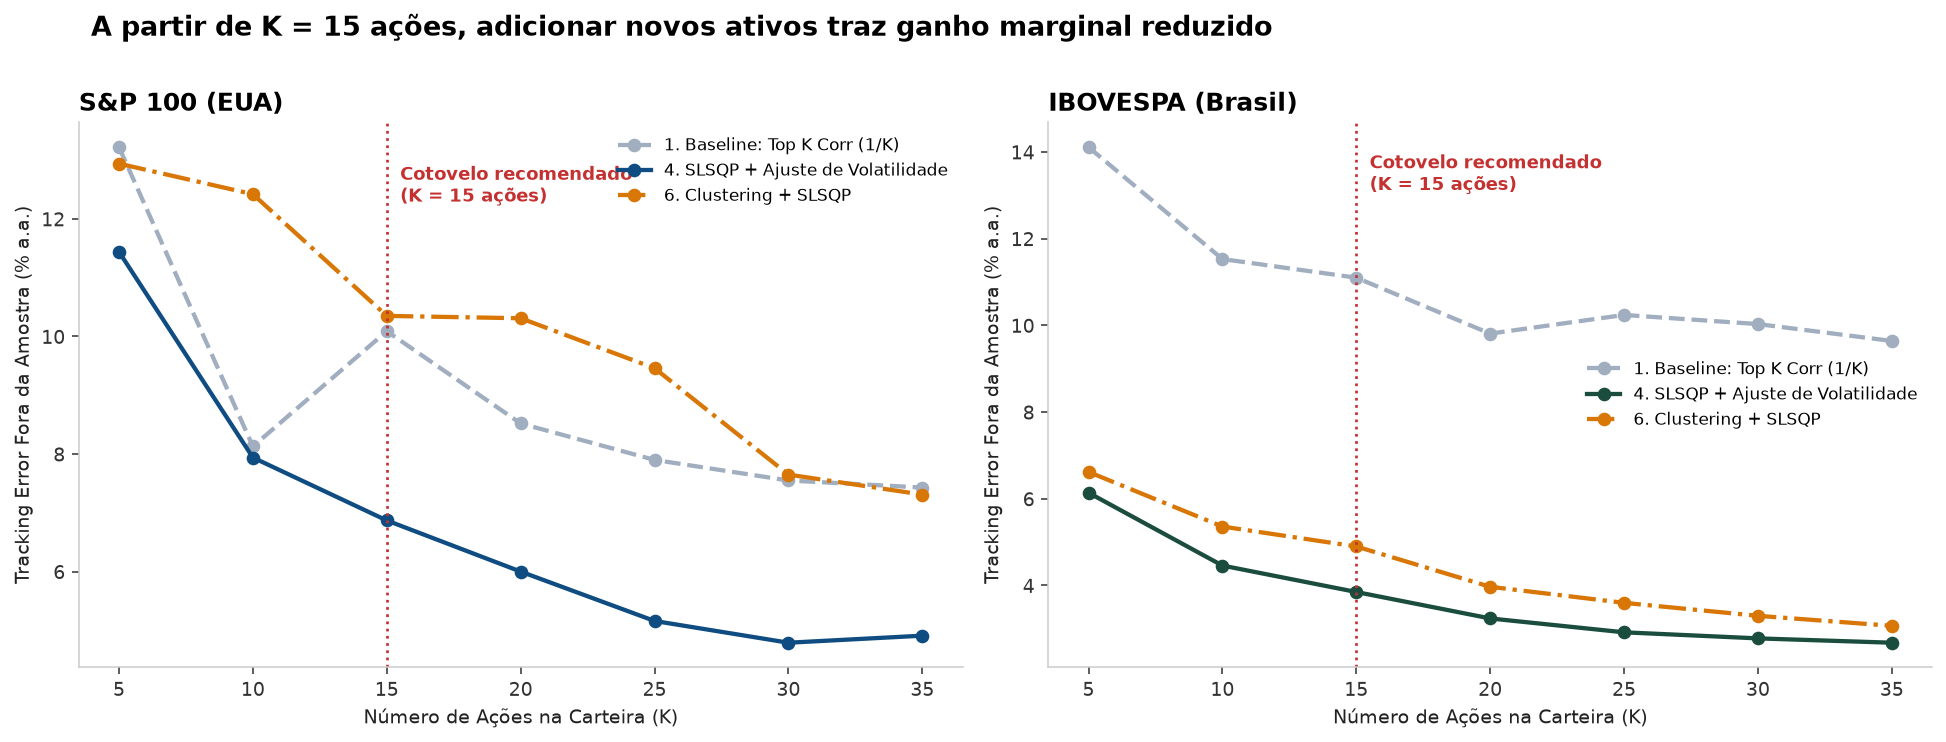

In [23]:
# 5.1 Curva de Tracking Error vs. Cardinalidade K (Escolha do Cotovelo K=15)
ks_grid = [5, 10, 15, 20, 25, 30, 35]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=140)
for ax, nome_m, tr_x, tr_y, oos_x, oos_y, mapa_s, cor_p in [
    (ax1, 'S&P 100 (EUA)', tr_X_sp, tr_y_sp, oos_X_sp, oos_y_sp, mapa_setores_sp, CORES['sp100']),
    (ax2, 'IBOVESPA (Brasil)', tr_X_ib, tr_y_ib, oos_X_ib, oos_y_ib, mapa_setores_ib, CORES['ibov'])
]:
    regs = []
    for k_i in ks_grid:
        for mod in ["1. Baseline: Top K Corr (1/K)", "4. SLSQP + Ajuste de Volatilidade", "6. Clustering + SLSQP"]:
            w_i = treinar_familia(mod, tr_x, tr_y, mapa_s, k=k_i)
            m_i = avaliar_carteira(w_i, oos_x, oos_y, mod)
            regs.append({'K': k_i, 'Modelo': mod, 'TE': m_i['TE OOS (% a.a.)']})
    df_k = pd.DataFrame(regs)
    for mod, ls, c in [
        ("1. Baseline: Top K Corr (1/K)", '--', CORES['neutro']),
        ("4. SLSQP + Ajuste de Volatilidade", '-', cor_p),
        ("6. Clustering + SLSQP", '-.', CORES['laranja'])
    ]:
        sub = df_k[df_k['Modelo'] == mod]
        ax.plot(sub['K'], sub['TE'], marker='o', ls=ls, color=c, lw=2.2, label=mod)
    ax.axvline(15, color=CORES['alerta'], ls=':', lw=1.4)
    ax.text(15.5, df_k['TE'].max()*0.93, 'Cotovelo recomendado\n(K = 15 ações)', color=CORES['alerta'], fontsize=9, fontweight='bold')
    ax.set_title(nome_m, loc='left', fontweight='bold')
    ax.set_xlabel('Número de Ações na Carteira (K)')
    ax.set_ylabel('Tracking Error Fora da Amostra (% a.a.)')
    ax.legend(frameon=False, fontsize=8.5)

plt.suptitle('A partir de K = 15 ações, adicionar novos ativos traz ganho marginal reduzido', x=0.05, y=1.01, fontweight='bold', fontsize=14, ha='left')
plt.tight_layout()
plt.show()


## 6. Validação Walk-Forward (Janela Móvel), Turnover e Modelos Finais
Na operação real de um fundo passivo, a carteira é rebalanceada periodicamente. Implementamos a validação *Walk-Forward* com **janela móvel de treino de 24 meses** e **rebalanceamento trimestral (a cada 3 meses)**, gerando **7 carteiras consecutivas fora da amostra** entre janeiro de 2025 e outubro de 2026 (atendendo ao requisito mínimo de 5 carteiras fora da amostra do briefing).

Além disso, incluímos a **suavização de Turnover** ($\lambda_{	ext{turn}}$) no otimizador SLSQP e descontamos um custo operacional de **0,10% (10 bps)** sobre o volume girado em cada trimestre.


In [24]:
def executar_walk_forward(ret_acoes, ret_idx, mapa_setores, k=15, janela_meses=24, passo_meses=3, lambda_turn=1e-4, custo_bps=10):
    inicio = pd.to_datetime('2025-01-01')
    pontos = pd.date_range(inicio, ret_acoes.index[-1], freq=f'{passo_meses}MS')
    if pontos[-1] < ret_acoes.index[-1]:
        pontos = pontos.union([ret_acoes.index[-1] + pd.Timedelta(days=1)])

    res_wf = []
    series_wf = {}
    ultimos_pesos = {}

    for mod in MODELOS_CANDIDATOS:
        ret_oos_bruto, ret_oos_liq, turnovers = [], [], []
        w_ant = pd.Series(dtype=float)

        for t0, t1 in zip(pontos[:-1], pontos[1:]):
            tr_x = ret_acoes.loc[t0 - pd.DateOffset(months=janela_meses): t0 - pd.Timedelta(days=1)]
            tr_y = ret_idx.loc[tr_x.index]

            w_novo = treinar_familia(mod, tr_x, tr_y, mapa_setores, k=k, w_ant=w_ant, lambda_turn=lambda_turn)
            if not w_ant.empty:
                uniao = w_novo.index.union(w_ant.index)
                turn = 0.5 * (w_novo.reindex(uniao, fill_value=0.0) - w_ant.reindex(uniao, fill_value=0.0)).abs().sum()
                turnovers.append(turn)
            else:
                turn = 1.0
            w_ant = w_novo

            bloco_x = ret_acoes.loc[t0: t1 - pd.Timedelta(days=1), w_novo.index]
            if len(bloco_x) > 0:
                rb = bloco_x @ w_novo
                rl = rb.copy()
                rl.iloc[0] -= turn * (custo_bps / 10000.0)
                ret_oos_bruto.append(rb)
                ret_oos_liq.append(rl)

        sb = pd.concat(ret_oos_bruto)
        sl = pd.concat(ret_oos_liq)
        si = ret_idx.loc[sb.index]

        te = (sb - si).std() * np.sqrt(252) * 100
        vol_c = sb.std() * np.sqrt(252) * 100
        vol_i = si.std() * np.sqrt(252) * 100
        gap_v = abs(vol_c - vol_i)
        corr = sb.corr(si)
        r2 = 1.0 - (((si - sb)**2).sum() / ((si - si.mean())**2).sum())
        td_b = ((np.exp(sb.sum()) - 1.0) - (np.exp(si.sum()) - 1.0)) * 100
        td_l = ((np.exp(sl.sum()) - 1.0) - (np.exp(si.sum()) - 1.0)) * 100

        series_wf[mod] = sl
        ultimos_pesos[mod] = w_ant
        res_wf.append({
            'Modelo': mod,
            'K': k,
            'TE Walk-Forward (% a.a.)': round(te, 2),
            'Gap Vol (p.p.)': round(gap_v, 2),
            'Correlação (r)': round(corr, 4),
            'R²': round(r2, 4),
            'Turnover Médio Trim. (%)': round(np.mean(turnovers)*100, 1),
            'TD Bruta (%)': round(td_b, 2),
            'TD Líquida (c/ custos %)': round(td_l, 2),
            'Carteiras OOS': len(turnovers) + 1
        })

    return pd.DataFrame(res_wf).set_index('Modelo'), series_wf, ultimos_pesos

df_wf_sp, series_wf_sp, pesos_finais_sp = executar_walk_forward(ret_sp100_clean, ret_idx_sp, mapa_setores_sp, k=15)
df_wf_ib, series_wf_ib, pesos_finais_ib = executar_walk_forward(ret_ibov_clean, ret_idx_ib, mapa_setores_ib, k=15)

print("=== VALIDAÇÃO WALK-FORWARD (7 CARTEIRAS TRIMESTRAIS FORA DA AMOSTRA, K=15) — S&P 100 ===")
display(df_wf_sp.sort_values('TE Walk-Forward (% a.a.)'))

print("\n=== VALIDAÇÃO WALK-FORWARD (7 CARTEIRAS TRIMESTRAIS FORA DA AMOSTRA, K=15) — IBOVESPA ===")
display(df_wf_ib.sort_values('TE Walk-Forward (% a.a.)'))


=== VALIDAÇÃO WALK-FORWARD (7 CARTEIRAS TRIMESTRAIS FORA DA AMOSTRA, K=15) — S&P 100 ===


,K,TE Walk-Forward (% a.a.),Gap Vol (p.p.),Correlação (r),R²,Turnover Médio Trim. (%),TD Bruta (%),TD Líquida (c/ custos %),Carteiras OOS
Modelo,,,,,,,,,
3. SLSQP Puro (Sem Redundância),15,4.63,0.87,0.9650,0.9310,18.0,-1.89,-2.16,7
4. SLSQP + Ajuste de Volatilidade,15,4.65,0.91,0.9647,0.9304,18.5,-2.15,-2.42,7
5. Lasso Positivo (L1 + SLSQP),15,7.36,3.29,0.9411,0.8254,14.1,2.97,2.73,7
6. Clustering + SLSQP,15,9.61,1.51,0.8414,0.7017,31.1,-17.66,-17.99,7
2. Baseline: Top K Inv-Vol (1/σ),15,10.01,7.04,0.9416,0.6771,12.8,3.55,3.31,7
1. Baseline: Top K Corr (1/K),15,11.78,8.85,0.9351,0.5523,11.1,13.04,12.79,7



=== VALIDAÇÃO WALK-FORWARD (7 CARTEIRAS TRIMESTRAIS FORA DA AMOSTRA, K=15) — IBOVESPA ===


,K,TE Walk-Forward (% a.a.),Gap Vol (p.p.),Correlação (r),R²,Turnover Médio Trim. (%),TD Bruta (%),TD Líquida (c/ custos %),Carteiras OOS
Modelo,,,,,,,,,
3. SLSQP Puro (Sem Redundância),15,3.38,0.53,0.9803,0.9583,9.3,3.82,3.57,7
4. SLSQP + Ajuste de Volatilidade,15,3.39,0.53,0.9803,0.9582,9.4,3.83,3.59,7
5. Lasso Positivo (L1 + SLSQP),15,4.43,1.30,0.9697,0.9277,13.6,20.81,20.49,7
6. Clustering + SLSQP,15,4.45,0.77,0.9633,0.9279,15.8,-3.24,-3.53,7
2. Baseline: Top K Inv-Vol (1/σ),15,9.78,6.39,0.9280,0.6516,8.5,14.90,14.64,7
1. Baseline: Top K Corr (1/K),15,10.41,7.06,0.9255,0.6055,7.8,9.36,9.12,7


In [25]:
# 6.1 Exportação dos Pesos Finais dos Modelos Campeões e Simulador de Boleta de Investimento
campeao_sp_nome = df_wf_sp['TE Walk-Forward (% a.a.)'].idxmin()
campeao_ib_nome = df_wf_ib['TE Walk-Forward (% a.a.)'].idxmin()

w_camp_sp = pesos_finais_sp[campeao_sp_nome].sort_values(ascending=False)
w_camp_ib = pesos_finais_ib[campeao_ib_nome].sort_values(ascending=False)

w_camp_sp.to_csv('pesos_campeao_sp100.csv', header=['Peso'])
w_camp_ib.to_csv('pesos_campeao_ibov.csv', header=['Peso'])

print(f"🏆 Modelo Campeão S&P 100  : {campeao_sp_nome} (TE Walk-Forward: {df_wf_sp.loc[campeao_sp_nome, 'TE Walk-Forward (% a.a.)']:.2f}% a.a.)")
print(f"🏆 Modelo Campeão IBOVESPA : {campeao_ib_nome} (TE Walk-Forward: {df_wf_ib.loc[campeao_ib_nome, 'TE Walk-Forward (% a.a.)']:.2f}% a.a.)")

def simular_boleta_investimento(pesos, df_precos, mapa_setores, valor_aporte=100000.0, moeda='R$'):
    ultimos_precos = df_precos.iloc[-1].loc[pesos.index]
    alocacao_teorica = pesos * valor_aporte
    qtd_acoes = np.floor(alocacao_teorica / ultimos_precos).astype(int)
    valor_investido = qtd_acoes * ultimos_precos

    df_boleta = pd.DataFrame({
        'Setor': [mapa_setores.get(t, 'Outros') for t in pesos.index],
        'Peso Alvo (%)': (pesos.values * 100).round(2),
        f'Última Cotação ({moeda})': ultimos_precos.values.round(2),
        f'Alocação Alvo ({moeda})': alocacao_teorica.values.round(2),
        'Qtd. Ações (Inteiras)': qtd_acoes.values,
        f'Valor Efetivo ({moeda})': valor_investido.values.round(2)
    }, index=[t.replace('.SA', '') for t in pesos.index])

    troco = valor_aporte - valor_investido.sum()
    print(f"\n--- Boleta de Investimento Simulado: {moeda} {valor_aporte:,.2f} (Caixa residual: {moeda} {troco:,.2f}) ---")
    display(df_boleta)
    return df_boleta

_ = simular_boleta_investimento(w_camp_sp, dados_sp100_clean, mapa_setores_sp, valor_aporte=50000.0, moeda='US$')
_ = simular_boleta_investimento(w_camp_ib, dados_ibov_clean, mapa_setores_ib, valor_aporte=100000.0, moeda='R$')


🏆 Modelo Campeão S&P 100  : 3. SLSQP Puro (Sem Redundância) (TE Walk-Forward: 4.63% a.a.)
🏆 Modelo Campeão IBOVESPA : 3. SLSQP Puro (Sem Redundância) (TE Walk-Forward: 3.38% a.a.)

--- Boleta de Investimento Simulado: US$ 50,000.00 (Caixa residual: US$ 2,169.72) ---


,Setor,Peso Alvo (%),Última Cotação (US$),Alocação Alvo (US$),Qtd. Ações (Inteiras),Valor Efetivo (US$)
MSFT,Tecnologia da Informação,11.90,512.80,5950.45,11,5640.80
AAPL,Tecnologia da Informação,10.90,330.32,5449.28,16,5285.12
NVDA,Tecnologia da Informação,9.81,230.86,4903.78,21,4848.06
KO,Consumo Básico,9.18,86.10,4590.98,53,4563.30
JPM,Financeiro,8.10,331.53,4050.31,12,3978.31
JNJ,Saúde,7.27,258.66,3636.43,14,3621.24
AMZN,Consumo Discricionário,6.96,248.23,3477.61,14,3475.22
GOOG,Serviços de Comunicação,6.72,334.93,3358.78,10,3349.30
CAT,Industrial,5.65,826.35,2826.20,3,2479.05
BRK-B,Financeiro,5.35,500.50,2677.15,5,2502.50



--- Boleta de Investimento Simulado: R$ 100,000.00 (Caixa residual: R$ 269.79) ---


,Setor,Peso Alvo (%),Última Cotação (R$),Alocação Alvo (R$),Qtd. Ações (Inteiras),Valor Efetivo (R$)
ITSA4,Financeiro,15.61,14.44,15605.48,1080,15595.20
PETR4,Petroleo Gas e Biocombustiveis,15.02,49.90,15018.04,300,14970.00
BRAP4,Materiais Basicos,10.17,20.33,10166.81,500,10165.00
SBSP3,Utilidade Publica,7.66,27.58,7661.32,277,7639.66
BBDC3,Financeiro,6.89,15.95,6888.98,431,6876.05
B3SA3,Financeiro,5.90,18.43,5904.43,320,5897.60
RDOR3,Saude,5.57,38.36,5572.99,145,5562.20
BPAC11,Financeiro,5.40,63.72,5397.64,84,5352.48
ABEV3,Consumo nao Ciclico,4.78,15.37,4783.93,311,4780.07
GOAU4,Materiais Basicos,4.60,11.24,4600.36,409,4597.16
